# 06B — Combine → NFL transfer: primary held-out benchmark

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing in this notebook has been run by its author. Every table and figure below is produced from out-of-fold predictions when you run it; no result is written in advance.

**Question.** Do frozen Combine movement representations improve the held-out prediction of frozen NFL movement outcomes beyond traditional Combine information?

**What would count as an answer.** For each frozen NFL target, on identical held-out athletes: the error of the official-Combine model M1, and the paired difference of every representation model against it, with a 95 % athlete-bootstrap interval. If the interval includes 0, an incremental predictive benefit is **not established** — that is a result, and the notebook is built to report it.

| Model | Predictors | Role |
|---|---|---|
| MEAN, POS | training-fold mean; position mean | sanity checks |
| M0 | position, draft cohort, pre-NFL body measurements | baseline context |
| **M1** | M0 + official Combine tests (+ missingness indicators) | **the scouting reference** |
| M2 | M1 + frozen engineered movement feature(s) | H1 |
| M3 | M1 + SPEED2 (p95 and interior peak speed) | simple speed control |
| M4 | M1 + fold-fitted FPCA scores | low-complexity learned reference |
| **M5** | M1 + fold-fitted TCN-B 8-d embedding | **H2, the primary comparison (M5 vs M1)** |
| M6 | M1 + random untrained encoder, same processing | does merely re-coding the curve explain a gain? |
| M7 | M1 + TCN-B on 2 / 4 training axes | exploratory; no dimension is selected |
| M5S | M1 + SPEED2 + TCN-B | H3: anything left once simple speed is in? |

**Prerequisite.** `06a_transfer_cohort_and_leakage_audit.ipynb` passed gate 06A in the same `RUN_MODE`. This notebook verifies the hashes of the frozen targets and of the fold table against that audit and refuses to run otherwise. PyTorch is required.

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'       # 'smoke' | 'full' — must match notebook 06A
FORCE_REBUILD = False    # True = refit the fold encoders and recompute every table
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True       # fold encoders trained here go to artifacts/models/advanced_movement/transfer/tcn (never notebook 03's)
SEED = 20261011          # seed of notebook 00; also the pre-declared primary training seed of TCN-B
DEVICE = 'auto'          # 'auto' | 'cpu' | 'cuda' (the encoders are small: CPU is enough)
BATCH_SIZE = 32          # used only if no notebook-03 checkpoint holds the encoder configuration
MAX_EPOCHS = None        # None = the training budget stored in the notebook-03 checkpoints (recommended)

ENCODER_SOURCE = 'auto'  # 'auto' = reuse a saved fold encoder ONLY where the 06A audit cleared it, train the others
                         # 'retrain' = train every fold encoder here on its training athletes
RUN_WIDE_COHORT = True   # M0 / M1 on athletes with official results and a target, tracking not required (labelled secondary)
RUN_SENSITIVITY = True   # attempt-aggregation rules and the elastic-net learner on the primary target (labelled exploratory)

## 0. Setup and hand-over from notebook 06A

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import fpca as fp
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import robust_train as rt
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import tcn
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_figures as tf
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_repr as trp
from nflbdb.research.advanced_movement import transfer_validation as tv
from nflbdb.research.advanced_movement.artifacts import TransferStore
from nflbdb.research.contracts import conform

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                save_models=SAVE_MODELS, device=DEVICE, seed=SEED, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS or 200).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
fcfg = fp.FpcaConfig().for_mode(controls)
tc = tr.TransferConfig().for_mode(controls)
store = TransferStore(cfg, controls)
up = store.upstream
device = amc.resolve_device(controls.device)
seed_notes = amc.seed_everything(controls.seed)

NB = {'00': '00_research_setup_and_data_audit.ipynb', '01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb',
      '03': '03_self_supervised_tcn.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb', '05A': '05a_nfl_movement_outcome_eda.ipynb',
      '06A': '06a_transfer_cohort_and_leakage_audit.ipynb'}
PROV = {'notebook': '06b_combine_to_nfl_transfer_benchmark.ipynb', 'run_mode': controls.run_mode, 'seed': controls.seed}

# ---- hand-over: frozen targets, folds and audit of 06A, verified against each other
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
targets, ocfg = tr.frozen_targets(registry_doc)
primary = tr.primary_target(targets)
folds = store.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(store, registry_doc, folds)          # raises when the targets or the folds changed since 06A
cohort = store.require(tr.COHORT, NB['06A'])
compat = store.require(tr.COMPAT, NB['06A'])
contract = store.read_json(tr.INPUT_CONTRACT, NB['06A'])
families, design_columns = contract['families'], contract['design_columns']
PRIMARY_INPUT, FPCA_K = contract['primary_input'], int(contract['fpca_k'])
FOLDS_HASH, TARGETS_HASH = audit['folds_hash'], registry_doc['version_hash']

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · device `{device}` · gate 06A `{audit["gate_06a"]}` · '
                 f'{audit["n_primary_cohort"]} primary-cohort athletes · {audit["n_folds"]} outer folds ({audit["fold_source"]}) · '
                 f'targets `{TARGETS_HASH}` frozen {registry_doc["frozen_at"]}'))
display(pl.DataFrame([{'target_id': t.target_id, 'role_in_this_study': t.study_role, 'unit': t.unit, 'context_adjustment': t.adjustment,
                       'min_windows': t.min_windows} for t in targets]))
display(store.describe())

**Run mode: `full`** (FULL) · device `cpu` · gate 06A `PASS` · 284 primary-cohort athletes · 5 outer folds (registry) · targets `8ff9fc191616711a` frozen 2026-10-13T11:09:49Z

target_id,role_in_this_study,unit,context_adjustment,min_windows
str,str,str,str,i64
"""O2.accel_sust05_mean""","""primary""","""yd/s²""","""cell_residual""",50
"""O3.band_acc_v0_2_mean""","""secondary_speed_conditioned""","""yd/s²""","""none""",50
"""O1.speed_p90_mean""","""secondary_speed""","""yd/s""","""none""",50


what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1. Synthetic validation of the modelling code

Eleven checks with a known answer: repeat-attempt aggregation, train-only preprocessing, per-fold target handling, out-of-fold uniqueness, paired model cohorts, regression metrics, the sign of Δ RMSE, the athlete bootstrap, FPCA fold isolation, embedding of unseen athletes, and TCN fold isolation (a saved encoder whose training athletes are held out must be refused). The last three train tiny encoders for a few epochs. **Every row must read `PASS`** before a real model is fitted; send the table if one fails.

In [3]:
validation_report = tv.run_all(tv.CHECKS_06B)
with pl.Config(tbl_rows=30, fmt_str_lengths=240):
    display(validation_report)
tv.assert_all_passed(validation_report)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\tcn.py:484: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  tot += (float(rec), float(cons), 1.0)
11:38:46 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN outer fold 0: trained, 6 epochs (best 6), 1.1 s
11:38:46 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN outer fold 1: trained, 6 epochs (best 6), 0.5 s
11:38:47 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN outer fold 0: trained, 6 epochs (best 6), 0.5 s
11:38:47 | INFO    | nflbdb.research.advanced_movement.transfer_repr | [advanced_movement:TRANSFER] TCN outer fold

check,status,detail
str,str,str
"""repeat_attempt_aggregation""","""PASS""","""the athlete mean, the first attempt in time and the reliability-weighted mean are exact; an athlete with one attempt is shrunk more; shrinkage parameters come from training athletes only; no rule can read an NFL value"""
"""train_only_preprocessing""","""PASS""","""medians, centres, scales, dummy levels and the ridge penalty depend on training athletes only: changing every held-out value leaves them identical; position effects are unpenalised; a missing embedding raises instead of being imputed"""
"""fold_target_handling""","""PASS""","""with all athletes the labels equal notebook 05's athlete outcomes (raw, context-adjusted, p90 and composite); with a training set the context means come from it alone, so held-out plays cannot move a training label; exposure rules keep time…"
"""oof_uniqueness""","""PASS""","""every athlete gets exactly one prediction per model, from the fold that held him out; the sanity model equals the training-fold mean; a missing or duplicated prediction and a missing label raise"""
"""paired_model_cohorts""","""PASS""","""paired comparisons require identical athletes AND identical labels for every model; a smaller cohort for one model, an extra engineered feature or a shared athlete between an encoder fit and its held-out fold each fail gate 06B"""
"""regression_metrics""","""PASS""","""RMSE, MAE, R² against the training mean, Spearman, Pearson and calibration reproduce hand-computed values; ridge and elastic net recover a known line"""
"""delta_rmse_sign""","""PASS""","""Δ RMSE = RMSE(reference) − RMSE(model): positive for the planted trait (+0.569, 50 %), about zero for a random block and for a copy of the forty, not established when the trait is removed"""
"""athlete_bootstrap""","""PASS""","""athletes — never plays or attempts — are resampled, with the same indices for both models of a comparison; intervals are reproducible for a seed and absent below the minimum cohort size; subgroup tables cover every athlete once"""
"""fpca_fold_isolation""","""PASS""","""FPCA support, mean and eigenfunctions of a fold come from its training athletes: tripling the held-out curves leaves every training score unchanged"""


## 2. Methodology — fixed before any model is fitted

**Unit.** One row = one athlete = one label. The sample size is the number of athletes in the paired cohort.

**For every outer fold**
1. training athletes and held-out athletes come from `transfer_outer_folds` (06A);
2. the label of every athlete is computed with context means estimated on the **training** athletes only (when the frozen target is context-adjusted);
3. representation encoders are fitted on training athletes only — FPCA support, mean and eigenfunctions; TCN-B normaliser, weights and early stopping; the random encoder's normaliser; the principal axes of the compact projection;
4. an athlete's representation is the **mean of his valid attempts** (frozen rule; `shrunk` and `first` are sensitivities) — never an NFL quantity;
5. imputation medians, centres, scales, dummy levels and missingness indicators are fitted on training athletes;
6. the ridge penalty is chosen on inner athlete-grouped folds **inside** the training athletes, from a fixed 13-point log grid, preprocessing refitted in each inner fold;
7. one prediction per held-out athlete is saved.

**Model.** Ridge regression. Position effects are additive and unpenalised; every other standardised term shares one penalty. The same learner, grid and folds are used for every model: no architecture search on a cohort of a few hundred athletes.

**Evaluation.** RMSE, MAE, out-of-sample R² (against the training-fold mean), Spearman, Pearson, calibration slope and intercept. Main comparison: **M5 vs M1**; M5 is also compared with M2, M3, M4 and M6, and M5S with M3.

$$\Delta\mathrm{RMSE} = \mathrm{RMSE}(\text{reference}) - \mathrm{RMSE}(\text{model}) \qquad \text{positive = lower error than the reference}$$

**Uncertainty.** Paired bootstrap of athletes on the out-of-fold table: both models of a comparison are resampled with the same athletes. Plays and attempts are never resampled as independent labels. The interval reflects which athletes were sampled, not the variability of refitting.

**Reading rule.** Statistical significance alone is not the criterion: effect size, relative gain, interval, complexity, stability across folds and coverage are read together. A gain below the declared practical margin, or carried by one fold, supports no scouting claim.

In [4]:
LADDER = tm.model_ladder(tc)
PAIRS = tm.comparisons(tc)
display(Markdown('**Model ladder**'))
with pl.Config(fmt_str_lengths=120, tbl_rows=20):
    display(pl.DataFrame([{'model': m.model, 'label': m.label, 'baseline_block': m.base, 'representation_blocks': ', '.join(m.families) or '—',
                           'role': m.role} for m in LADDER]))
display(Markdown('**Comparisons declared in advance** (model vs reference)'))
display(pl.DataFrame({'model': [m for m, _ in PAIRS], 'reference': [r for _, r in PAIRS]}))
display(Markdown(f'**Ridge penalty grid:** {np.array2string(tc.alphas, precision=3)} · inner folds {tc.inner_folds} · bootstrap replicates {tc.n_boot} · '
                 f'practical margin {100 * tc.min_relative_gain:g} % of the reference error (heuristic)  \n'
                 f'**Baseline predictors (from 06A, coverage only):** M0 {design_columns["m0_numeric"]} · M1 {design_columns["m1_numeric"]} · '
                 f'indicators {design_columns["indicators"]}'))

**Model ladder**

model,label,baseline_block,representation_blocks,role
str,str,str,str,str
"""MEAN""","""training-fold mean""","""none""","""—""","""sanity"""
"""POS""","""position mean""","""position""","""—""","""sanity"""
"""M0""","""M0 · context (position, cohort, body)""","""M0""","""—""","""baseline"""
"""M1""","""M1 · official Combine""","""M1""","""—""","""reference"""
"""M2""","""M2 · M1 + engineered movement""","""M1""","""ENG""","""candidate"""
"""M3""","""M3 · M1 + SPEED2""","""M1""","""SPEED2""","""control"""
"""M4""","""M4 · M1 + FPCA""","""M1""","""FPCA""","""candidate"""
"""M5""","""M5 · M1 + TCN-B (8-d)""","""M1""","""TCN""","""candidate"""
"""M6""","""M6 · M1 + random encoder""","""M1""","""RAND""","""control"""


**Comparisons declared in advance** (model vs reference)

model,reference
str,str
"""POS""","""MEAN"""
"""M0""","""POS"""
"""M1""","""M0"""
"""M2""","""M1"""
"""M3""","""M1"""
…,…
"""M5""","""M4"""
"""M5""","""M6"""
"""M5S""","""M3"""


**Ridge penalty grid:** [1.000e-02 3.162e-02 1.000e-01 3.162e-01 1.000e+00 3.162e+00 1.000e+01
 3.162e+01 1.000e+02 3.162e+02 1.000e+03 3.162e+03 1.000e+04] · inner folds 5 · bootstrap replicates 2000 · practical margin 2 % of the reference error (heuristic)  
**Baseline predictors (from 06A, coverage only):** M0 ['cmb_combine_weight', 'cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span'] · M1 ['cmb_combine_weight', 'cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span', 'cmb_forty', 'cmb_ten_yd_split', 'cmb_vertical', 'cmb_broad_jump'] · indicators ['cmb_combine_height', 'cmb_hand_size', 'cmb_arm_length', 'cmb_wing_span', 'cmb_vertical', 'cmb_broad_jump']

## 3. Data: curves, labels and design

The same persisted tables as 06A. The play table of notebook 05A now provides label **values**, through `TargetSet`, which hands a label to a model only together with the training athletes whose context means it may use.

In [5]:
manifest = up.require(amd.MANIFEST, NB['00'])
athletes = up.require(amd.ATHLETES, NB['00'])
splits = up.require(amd.SPLITS, NB['00'])
seq_frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)

ss = seq.SequenceSet.from_frames(seq_frames, manifest)
curves = fp.build_curves(ss, acfg, fp.SPEC[PRIMARY_INPUT])
tset = tr.TargetSet(plays, ocfg, targets)
enc_splits = tr.encoder_splits(folds, splits)
tr.assert_fold_integrity(folds, enc_splits, manifest)
design_all = tm.Design.build(folds, official, design_columns)                 # the 06A primary cohort
FOLD_IDS = sorted(np.unique(design_all.fold).tolist())
ORDER = dict(windows.select('seq_id', 'attempt_order').iter_rows())           # seq_id → 1 = first attempt in time
display(Markdown(f'**{curves.n} attempts of {np.unique(curves.nfl_ids).size} tracked athletes** on input `{PRIMARY_INPUT}` · '
                 f'{design_all.n} athletes in the 06A primary cohort · outer folds {FOLD_IDS} · {tset.ids.size} athletes with NFL windows'))

**793 attempts of 418 tracked athletes** on input `A_speed_by_distance` · 284 athletes in the 06A primary cohort · outer folds [0, 1, 2, 3, 4] · 401 athletes with NFL windows

## 4. Fold-safe representations

For each outer fold, each family is produced for every tracked attempt by something fitted on the fold's training athletes only. Tracked athletes without NFL data are unlabelled Combine data: under registry folds they are held out in their own fold exactly as in notebook 03; under new folds they are never held out.

- **TCN-B** uses the frozen configuration of notebook 03 (read from its checkpoints) — no architecture, objective or budget is changed here. A saved fold encoder is reused only where the 06A audit found no held-out transfer athlete in its fit, early-stopping or normalisation athletes, and that disjointness is re-asserted when the file is loaded. Every other fold is trained here. The saved all-athlete embedding tables are not read: embeddings are recomputed from the encoder.
- **FPCA** is refitted per fold (deterministic, seconds) with the benchmark K of notebook 02.
- **Random encoder**: same architecture and code path, weights never trained.
- **ENG / SPEED2**: per-attempt scalars from the atlas; nothing is fitted.

The stage is cached. Its key holds the fold manifest hash, the encoder configuration, the seed, the reuse map and the state of the input files; trained encoders are saved under `artifacts/models/advanced_movement/transfer/tcn/`.

In [6]:
tcfg_exec = rt.executed_config(up.models_dir, families['TCN'])
config_source = 'read from the checkpoints of notebook 03'
if tcfg_exec is None:
    tcfg_exec = rt.reconstructed_config(up.require(tcn.DESIGN, NB['03']), controls, fcfg)
    config_source = 'RECONSTRUCTED from the design sweep of notebook 03 (no checkpoint found): equal to notebook 03 only if BATCH_SIZE and MAX_EPOCHS match'
tcfg = tcfg_exec if MAX_EPOCHS is None else replace(tcfg_exec, max_epochs=int(MAX_EPOCHS))

reuse = {}
if ENCODER_SOURCE == 'auto':
    reuse = {('TCN', f): str(cfg.paths.project_root / p) for f, p in tr.reusable_checkpoints(compat, families['TCN']).items() if f in FOLD_IDS}
elif ENCODER_SOURCE != 'retrain':
    raise ValueError('ENCODER_SOURCE must be auto or retrain')

scalars = {'ENG': trp.scalar_matrix(attempt_values, families['ENG'], curves.seq_ids),
           'SPEED2': trp.scalar_matrix(attempt_values, families['SPEED2'], curves.seq_ids)}
plan = trp.RepPlan(tcfg, fcfg, FPCA_K, controls.seed, families=('ENG', 'SPEED2', 'FPCA', 'TCN', 'RAND'), compact_dims=tc.compact_dims)
REP_FILES = [up.parquet(seq.SEQ_FRAMES), up.parquet(amd.SPLITS), store.parquet(tr.FOLDS), store.atlas.parquet(at.ATTEMPT_VALUES)]
REP_PARAMS = {'folds_hash': FOLDS_HASH, 'config': acfg.params(), 'input': PRIMARY_INPUT, 'seed': controls.seed,
              'features': {'ENG': families['ENG'], 'SPEED2': families['SPEED2']}, 'encoder_source': ENCODER_SOURCE}

display(Markdown(f'**Encoder configuration:** {config_source}. Saved fold encoders reused: folds {sorted(f for _, f in reuse)} of {FOLD_IDS}; '
                 f'the others are trained now on `{device}`.'))
rep = trp.build_representations(store, 'REP_OUTER', 'outer', curves, enc_splits, FOLD_IDS, plan, scalars, device, reuse, 'outer', REP_PARAMS, REP_FILES)
attempts, enc_fits = rep[trp.ATTEMPT_REP.name], rep[trp.ENC_FITS.name]
display(Markdown('**How each representation of each fold was obtained** (`n_overlap` must be 0 everywhere)'))
with pl.Config(tbl_rows=80, fmt_str_lengths=60):
    display(enc_fits.select('family', 'fold', 'source', 'n_train_athletes', 'n_heldout_athletes', 'n_overlap', 'n_attempts_valid', 'n_heldout_valid',
                            'embedding_dim', 'best_epoch', 'train_seconds').sort('family', 'fold'))
if int(enc_fits['n_overlap'].sum()):
    raise tr.TransferGateError('a representation fit shares athletes with its held-out fold')

**Encoder configuration:** read from the checkpoints of notebook 03. Saved fold encoders reused: folds [0, 1, 2, 3, 4] of [0, 1, 2, 3, 4]; the others are trained now on `cpu`.

11:38:49 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:REP_OUTER] computing (never run)
11:38:51 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REP_OUTER] transfer_attempt_representations_outer: 107,055 rows → warehouse/gold/advanced_movement/transfer/transfer_attempt_representations_outer.parquet
11:38:51 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:REP_OUTER] transfer_encoder_fits_outer: 35 rows → warehouse/gold/advanced_movement/transfer/transfer_encoder_fits_outer.parquet


**How each representation of each fold was obtained** (`n_overlap` must be 0 everywhere)

family,fold,source,n_train_athletes,n_heldout_athletes,n_overlap,n_attempts_valid,n_heldout_valid,embedding_dim,best_epoch,train_seconds
str,i64,str,i64,i64,i64,i64,i64,i64,i64,f64
"""ENG""",0,"""deterministic""",334,84,0,793,158,1,null,null
"""ENG""",1,"""deterministic""",334,84,0,793,162,1,null,null
"""ENG""",2,"""deterministic""",334,84,0,793,163,1,null,null
"""ENG""",3,"""deterministic""",335,83,0,793,157,1,null,null
"""ENG""",4,"""deterministic""",335,83,0,793,153,1,null,null
"""FPCA""",0,"""fitted""",334,84,0,793,158,2,null,null
"""FPCA""",1,"""fitted""",334,84,0,793,162,2,null,null
"""FPCA""",2,"""fitted""",334,84,0,793,163,2,null,null
"""FPCA""",3,"""fitted""",335,83,0,793,157,2,null,null


## 5. Paired cohort (common support)

The 06A primary cohort required a recorded curve. Whether a fold's encoder can embed an attempt also depends on that fold's training support, so the final check is made here: an athlete stays in the **paired cohort** only if every representation family exists for him under **every** fold model. An athlete who does not is dropped with the blocks he lacks — his embedding is never imputed, and the folds are kept as assigned.

All models, including M0 and M1, are then evaluated on this one cohort. A model with fewer missing inputs gets no larger population.

In [7]:
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
HAVE = set(blocks.families())
MODELS = [m for m in LADDER if all(f in HAVE for f in m.families)]
skipped = [m.model for m in LADDER if m not in MODELS]
FAMS = sorted({f for m in MODELS for f in m.families})
support = tm.common_support(design_all, blocks, FAMS)
support = store.write(support, tm.SUPPORT, '06B', PROV) if controls.save_tables else conform(support, tm.SUPPORT)
d = design_all.keep_ids(support.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
DIMS = {f: int(blocks.athlete(f, FOLD_IDS[0])[1].shape[1]) for f in FAMS}

dropped = support.filter(~pl.col('in_paired_cohort'))
display(Markdown(f'**Paired cohort: {d.n} athletes** of the {design_all.n} in the 06A primary cohort · {dropped.height} dropped for a missing '
                 f'representation · block sizes {DIMS}' + (f' · models not evaluable (empty frozen slot): {skipped}' if skipped else '')))
if dropped.height:
    with pl.Config(fmt_str_lengths=120):
        display(dropped)
if d.n < tc.min_athletes:
    raise tr.TransferGateError(f'only {d.n} athletes in the paired cohort (minimum {tc.min_athletes})')
display(pl.DataFrame({'position_group': d.position, 'draft_year': d.cohort, 'fold': d.fold}).group_by('position_group', 'draft_year').len()
        .pivot(on='draft_year', index='position_group', values='len').sort('position_group'))

11:38:51 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06B] transfer_common_support: 284 rows → warehouse/gold/advanced_movement/transfer/transfer_common_support.parquet


**Paired cohort: 284 athletes** of the 284 in the 06A primary cohort · 0 dropped for a missing representation · block sizes {'ENG': 1, 'FPCA': 2, 'RAND': 8, 'SPEED2': 2, 'TCN': 8, 'TCN_PC2': 2, 'TCN_PC4': 4}

position_group,2024,2025,2023
str,u32,u32,u32
"""DB""",26,18,23
"""DL""",23,20,27
"""OL""",24,19,20
"""TE""",7,5,8
"""WR""",23,16,25


## 6. Out-of-fold predictions

Every frozen target is run through the same loop on the paired cohort, restricted to the athletes meeting **that target's** frozen exposure requirement (identically for every model).

| Analysis label | What changes | Status |
|---|---|---|
| `primary` / cohort `primary` | nothing: the pre-declared benchmark | confirmatory for the primary target, secondary for the others |
| `primary` / cohort `official_wide` | M0 and M1 on athletes with official results and a target, tracking not required | secondary — a different population, never mixed with the paired comparison |
| `agg:shrunk`, `agg:first` | how an athlete's attempts are combined | exploratory sensitivity (primary target) |
| `learner:enet` | elastic net instead of ridge | exploratory sensitivity (primary target) |

Results of the exploratory rows cannot replace the primary conclusion.

In [8]:
OOF_C = [tm.OOF, tm.OOF_TARGETS, tm.PREP]
OOF_PARAMS = {'folds_hash': FOLDS_HASH, 'targets_hash': TARGETS_HASH, 'transfer_config': tc.params(), 'models': [m.model for m in MODELS],
              'design_columns': design_columns, 'representations': {**REP_PARAMS, 'plan': plan.params()}, 'paired_cohort': int(d.n),
              'wide': RUN_WIDE_COHORT, 'sensitivity': RUN_SENSITIVITY}
OOF_FILES = [store.parquet(trp.named(trp.ATTEMPT_REP, 'outer')), store.nfl.parquet(no.plays_contract(ocfg)), store.parquet(tr.FOLDS)]

def build_oof():
    parts = [tm.run_analysis(tm.PRIMARY, t, d, tset, blocks, MODELS, tc) for t in targets]
    if RUN_WIDE_COHORT:
        wide = tm.Design.build(folds, official, design_columns, primary_only=False)
        base = [m for m in MODELS if not m.families]
        parts += [tm.run_analysis(tm.PRIMARY, t, wide, tset, tm.ArrayBlocks(wide.ids, {}), base, tc, cohort='official_wide') for t in targets]
    if RUN_SENSITIVITY:
        for how in [a for a in tc.aggregations if a != tc.aggregation]:
            parts.append(tm.run_analysis(f'agg:{how}', primary, d, tset, tm.RepBlocks(attempts, ORDER, 'outer', how), MODELS, tc))
        parts.append(tm.run_analysis('learner:enet', primary, d, tset, blocks, MODELS, tc, learner='enet'))
    return tm.concat(parts, OOF_C)

out = store.build('OOF_PRIMARY', OOF_C, build_oof, params=OOF_PARAMS, files=OOF_FILES)
oof, labels, prep = out[tm.OOF.name], out[tm.OOF_TARGETS.name], out[tm.PREP.name]
display(Markdown('**Out-of-fold table** (unit: athlete; one prediction per athlete, model, target and analysis)'))
display(oof.group_by('analysis', 'cohort', 'target_id').agg(pl.col('nfl_id').n_unique().alias('n_athletes'), pl.col('model').n_unique().alias('n_models'),
                                                            pl.col('position_group').n_unique().alias('n_positions'),
                                                            pl.col('draft_year').n_unique().alias('n_cohorts'), pl.len().alias('rows'))
        .sort('cohort', 'analysis', 'target_id'))
display(Markdown('**Ridge penalty chosen inside the training athletes** (primary analysis; median over folds)'))
display(oof.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY) & pl.col('alpha').is_not_null())
        .group_by('target_id', 'model').agg(pl.col('alpha').median().alias('median_alpha'), pl.col('alpha').min().alias('min'), pl.col('alpha').max().alias('max'))
        .sort('target_id', 'model'))

11:38:51 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:OOF_PRIMARY] computing (never run)
11:41:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_PRIMARY] transfer_oof_predictions: 23,892 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_predictions.parquet
11:41:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_PRIMARY] transfer_oof_targets: 2,565 rows → warehouse/gold/advanced_movement/transfer/transfer_oof_targets.parquet
11:41:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:OOF_PRIMARY] transfer_fold_preprocessing: 6,630 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_preprocessing.parquet


**Out-of-fold table** (unit: athlete; one prediction per athlete, model, target and analysis)

analysis,cohort,target_id,n_athletes,n_models,n_positions,n_cohorts,rows
str,str,str,u32,u32,u32,u32,u32
"""primary""","""official_wide""","""O1.speed_p90_mean""",287,4,5,3,1148
"""primary""","""official_wide""","""O2.accel_sust05_mean""",287,4,5,3,1148
"""primary""","""official_wide""","""O3.band_acc_v0_2_mean""",287,4,5,3,1148
"""agg:first""","""primary""","""O2.accel_sust05_mean""",284,12,5,3,3408
"""agg:shrunk""","""primary""","""O2.accel_sust05_mean""",284,12,5,3,3408
"""learner:enet""","""primary""","""O2.accel_sust05_mean""",284,12,5,3,3408
"""primary""","""primary""","""O1.speed_p90_mean""",284,12,5,3,3408
"""primary""","""primary""","""O2.accel_sust05_mean""",284,12,5,3,3408
"""primary""","""primary""","""O3.band_acc_v0_2_mean""",284,12,5,3,3408


**Ridge penalty chosen inside the training athletes** (primary analysis; median over folds)

target_id,model,median_alpha,min,max
str,str,f64,f64,f64
"""O1.speed_p90_mean""","""M0""",1.0,0.316228,1.0
"""O1.speed_p90_mean""","""M1""",1.0,0.316228,3.162278
"""O1.speed_p90_mean""","""M2""",3.162278,0.316228,3.162278
"""O1.speed_p90_mean""","""M3""",1.0,0.01,3.162278
"""O1.speed_p90_mean""","""M4""",1.0,1.0,3.162278
…,…,…,…,…
"""O3.band_acc_v0_2_mean""","""M5""",3.162278,3.162278,31.622777
"""O3.band_acc_v0_2_mean""","""M5S""",3.162278,3.162278,31.622777
"""O3.band_acc_v0_2_mean""","""M6""",3.162278,3.162278,31.622777


## 7. Performance and paired comparisons

Tables first, figures after. For each target: the held-out performance of every model, then the paired differences. `established` = the 95 % interval of the difference lies above 0; `worse` = it lies below 0; neither = **not established**.

In [9]:
EVAL_C = [tm.PERF, tm.PAIRED, tm.FOLD_PERF]

def build_eval():
    ev = tm.evaluate(oof, PAIRS, tc, controls.seed)
    return {tm.PERF.name: ev[tm.PERF.name], tm.PAIRED.name: ev[tm.PAIRED.name], tm.FOLD_PERF.name: tm.fold_performance(oof)}

ev = store.build('EVAL_PRIMARY', EVAL_C, build_eval, params={**OOF_PARAMS, 'pairs': [list(p) for p in PAIRS]}, files=[store.parquet(tm.OOF)])
perf, paired, fold_perf = ev[tm.PERF.name], ev[tm.PAIRED.name], ev[tm.FOLD_PERF.name]

def show_target(t, cohort_label=tm.PRIMARY, analysis=tm.PRIMARY):
    p = perf.filter((pl.col('analysis') == analysis) & (pl.col('cohort') == cohort_label) & (pl.col('target_id') == t.target_id))
    if not p.height:
        display(Markdown(f'`{t.target_id}` — not evaluated ({analysis}, {cohort_label}): too few eligible athletes'))
        return
    r = p.row(0, named=True)
    display(Markdown(f'### `{t.target_id}` — {t.label} ({t.unit}) · role: {t.study_role} · cohort: {cohort_label}\n'
                     f'{r["n_athletes"]} athletes · {r["n_positions"]} position groups · {r["n_cohorts"]} draft cohorts'))
    wide = p.pivot(on='metric', index='model', values='estimate')
    ci = p.filter(pl.col('metric') == 'rmse').select('model', pl.col('ci_lower').alias('rmse_lower'), pl.col('ci_upper').alias('rmse_upper'))
    order = {m: i for i, m in enumerate(tf.MODEL_ORDER)}
    display(wide.join(ci, on='model', how='left').with_columns(pl.col('model').replace_strict(order, default=99).alias('_o')).sort('_o').drop('_o')
            .select('model', 'rmse', 'rmse_lower', 'rmse_upper', 'mae', 'r2_oos', 'spearman', 'pearson', 'calibration_slope', 'calibration_intercept'))
    q = paired.filter((pl.col('analysis') == analysis) & (pl.col('cohort') == cohort_label) & (pl.col('target_id') == t.target_id)
                      & (pl.col('metric') == 'delta_rmse'))
    display(q.select('model', 'reference', pl.col('estimate').alias('delta_rmse'), 'ci_lower', 'ci_upper', 'relative', 'share_boot_improved',
                     'established', 'worse').sort('reference', 'model'))

with pl.Config(tbl_rows=40, float_precision=4):
    for t in targets:
        show_target(t)

11:41:03 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:EVAL_PRIMARY] computing (never run)
11:42:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:EVAL_PRIMARY] transfer_model_performance: 588 rows → warehouse/gold/advanced_movement/transfer/transfer_model_performance.parquet
11:42:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:EVAL_PRIMARY] transfer_paired_comparisons: 468 rows → warehouse/gold/advanced_movement/transfer/transfer_paired_comparisons.parquet
11:42:03 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:EVAL_PRIMARY] transfer_fold_performance: 420 rows → warehouse/gold/advanced_movement/transfer/transfer_fold_performance.parquet


### `O2.accel_sust05_mean` — sustained acceleration, 0.5 s (mean of windows) (yd/s²) · role: primary · cohort: primary
284 athletes · 5 position groups · 3 draft cohorts

model,rmse,rmse_lower,rmse_upper,mae,r2_oos,spearman,pearson,calibration_slope,calibration_intercept
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""MEAN""",0.7776,0.7272,0.8246,0.6427,0.0000,-0.0785,-0.0594,-4.2413,18.6611
"""POS""",0.1815,0.1559,0.2079,0.1326,0.9455,0.9361,0.9723,0.9966,0.0134
"""M0""",0.1797,0.1548,0.2055,0.1317,0.9466,0.9500,0.9729,0.9984,0.0069
"""M1""",0.1794,0.1542,0.2049,0.1321,0.9468,0.9494,0.9730,0.9967,0.0132
"""M2""",0.1793,0.1540,0.2047,0.1321,0.9468,0.9495,0.9730,0.9968,0.0129
"""M3""",0.1797,0.1543,0.2053,0.1324,0.9466,0.9492,0.9729,0.9964,0.0143
"""M4""",0.1798,0.1542,0.2051,0.1324,0.9466,0.9498,0.9729,0.9968,0.0130
"""M5""",0.1791,0.1535,0.2046,0.1317,0.9469,0.9492,0.9731,0.9974,0.0103
"""M6""",0.1794,0.1538,0.2048,0.1323,0.9468,0.9491,0.9730,0.9966,0.0132


model,reference,delta_rmse,ci_lower,ci_upper,relative,share_boot_improved,established,worse
str,str,f64,f64,f64,f64,f64,bool,bool
"""M1""","""M0""",0.0003,-0.0021,0.0026,0.0014,0.6005,false,false
"""M2""","""M1""",0.0001,-0.0002,0.0004,0.0005,0.7385,false,false
"""M3""","""M1""",-0.0003,-0.0009,0.0002,-0.0017,0.1180,false,false
"""M4""","""M1""",-0.0003,-0.0009,0.0001,-0.0019,0.0835,false,false
"""M5""","""M1""",0.0003,-0.0008,0.0015,0.0016,0.6720,false,false
"""M5S""","""M1""",-0.0004,-0.0015,0.0006,-0.0024,0.2110,false,false
"""M6""","""M1""",0.0001,-0.0012,0.0013,0.0003,0.5300,false,false
"""M7_PC2""","""M1""",-0.0001,-0.0006,0.0004,-0.0004,0.3935,false,false
"""M7_PC4""","""M1""",0.0001,-0.0012,0.0015,0.0007,0.5850,false,false


### `O3.band_acc_v0_2_mean` — acceleration from 0–2 yd/s (mean of windows) (yd/s²) · role: secondary_speed_conditioned · cohort: primary
284 athletes · 5 position groups · 3 draft cohorts

model,rmse,rmse_lower,rmse_upper,mae,r2_oos,spearman,pearson,calibration_slope,calibration_intercept
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""MEAN""",0.7600,0.7128,0.8059,0.6373,0.0000,-0.0720,-0.0646,-4.1931,12.0184
"""POS""",0.2291,0.2088,0.2497,0.1761,0.9092,0.8675,0.9534,0.9979,0.0047
"""M0""",0.1929,0.1741,0.2123,0.1506,0.9356,0.9329,0.9672,0.9988,0.0022
"""M1""",0.1915,0.1733,0.2099,0.1496,0.9365,0.9312,0.9677,0.9972,0.0046
"""M2""",0.1919,0.1740,0.2107,0.1507,0.9362,0.9302,0.9675,0.9965,0.0064
"""M3""",0.1921,0.1738,0.2107,0.1500,0.9361,0.9308,0.9675,0.9950,0.0107
"""M4""",0.1918,0.1735,0.2107,0.1498,0.9363,0.9318,0.9676,0.9944,0.0116
"""M5""",0.1916,0.1730,0.2105,0.1483,0.9365,0.9291,0.9677,1.0020,-0.0093
"""M6""",0.1933,0.1753,0.2118,0.1517,0.9353,0.9262,0.9671,0.9911,0.0182


model,reference,delta_rmse,ci_lower,ci_upper,relative,share_boot_improved,established,worse
str,str,f64,f64,f64,f64,f64,bool,bool
"""M1""","""M0""",0.0014,-0.0040,0.0071,0.0074,0.6925,false,false
"""M2""","""M1""",-0.0005,-0.0016,0.0007,-0.0024,0.1990,false,false
"""M3""","""M1""",-0.0006,-0.0022,0.0009,-0.0032,0.2040,false,false
"""M4""","""M1""",-0.0003,-0.0023,0.0016,-0.0015,0.3915,false,false
"""M5""","""M1""",-0.0001,-0.0051,0.0050,-0.0004,0.4775,false,false
"""M5S""","""M1""",0.0016,-0.0038,0.0069,0.0086,0.7235,false,false
"""M6""","""M1""",-0.0018,-0.0056,0.0018,-0.0094,0.1645,false,false
"""M7_PC2""","""M1""",0.0014,-0.0012,0.0040,0.0072,0.8550,false,false
"""M7_PC4""","""M1""",0.0005,-0.0037,0.0048,0.0027,0.5900,false,false


### `O1.speed_p90_mean` — play p90 speed (mean of windows) (yd/s) · role: secondary_speed · cohort: primary
284 athletes · 5 position groups · 3 draft cohorts

model,rmse,rmse_lower,rmse_upper,mae,r2_oos,spearman,pearson,calibration_slope,calibration_intercept
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""MEAN""",1.3964,1.3218,1.4642,1.2176,0.0000,-0.0906,-0.0908,-4.1651,25.2003
"""POS""",0.3201,0.2909,0.3490,0.2429,0.9475,0.9366,0.9733,0.9992,0.0036
"""M0""",0.2712,0.2406,0.3003,0.2021,0.9623,0.9635,0.9809,0.9979,0.0102
"""M1""",0.2754,0.2449,0.3049,0.2042,0.9611,0.9626,0.9803,0.9947,0.0270
"""M2""",0.2753,0.2444,0.3043,0.2044,0.9611,0.9624,0.9803,0.9954,0.0229
"""M3""",0.2726,0.2422,0.3015,0.2030,0.9619,0.9633,0.9807,0.9948,0.0271
"""M4""",0.2740,0.2438,0.3031,0.2042,0.9615,0.9629,0.9805,0.9946,0.0273
"""M5""",0.2740,0.2442,0.3031,0.2051,0.9615,0.9626,0.9805,0.9948,0.0228
"""M6""",0.2778,0.2478,0.3065,0.2070,0.9604,0.9626,0.9800,0.9915,0.0436


model,reference,delta_rmse,ci_lower,ci_upper,relative,share_boot_improved,established,worse
str,str,f64,f64,f64,f64,f64,bool,bool
"""M1""","""M0""",-0.0041,-0.0099,0.0015,-0.0153,0.0730,false,false
"""M2""","""M1""",0.0001,-0.0012,0.0013,0.0002,0.5235,false,false
"""M3""","""M1""",0.0028,-0.0009,0.0069,0.0102,0.9315,false,false
"""M4""","""M1""",0.0013,-0.0012,0.0040,0.0048,0.8430,false,false
"""M5""","""M1""",0.0014,-0.0051,0.0077,0.0050,0.6555,false,false
"""M5S""","""M1""",0.0012,-0.0052,0.0074,0.0042,0.6375,false,false
"""M6""","""M1""",-0.0025,-0.0088,0.0042,-0.0089,0.2455,false,false
"""M7_PC2""","""M1""",0.0040,-0.0001,0.0083,0.0145,0.9705,false,false
"""M7_PC4""","""M1""",-0.0006,-0.0072,0.0058,-0.0022,0.4305,false,false


In [10]:
with pl.Config(tbl_rows=40, float_precision=4):
    if RUN_WIDE_COHORT:
        display(Markdown('## Secondary — official results on the wide cohort\nA different, larger population (tracking not required). It shows what official '
                         'testing predicts when no tracked attempt is needed; it is not comparable row by row with the paired cohort.'))
        for t in targets:
            show_target(t, cohort_label='official_wide')
    if RUN_SENSITIVITY:
        display(Markdown('## Exploratory — aggregation rule and learner (primary target)\nΔ RMSE of each model against M1 under each variant. '
                         'A conclusion that appears under one variant only is not confirmed.'))
        s = paired.filter((pl.col('cohort') == tm.PRIMARY) & (pl.col('target_id') == primary.target_id) & (pl.col('reference') == tm.REFERENCE)
                          & (pl.col('metric') == 'delta_rmse'))
        display(s.pivot(on='analysis', index='model', values='estimate').sort('model'))
        display(s.filter(pl.col('model') == 'M5').select('analysis', 'n_athletes', pl.col('estimate').alias('delta_rmse_M5_vs_M1'), 'ci_lower', 'ci_upper',
                                                         'established').sort('analysis'))
    display(Markdown('**Performance by outer fold** (primary target; Δ RMSE against M1 inside the fold)'))
    display(fold_perf.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY) & (pl.col('target_id') == primary.target_id))
            .pivot(on='fold', index='model', values='delta_rmse_vs_m1').sort('model'))

## Secondary — official results on the wide cohort
A different, larger population (tracking not required). It shows what official testing predicts when no tracked attempt is needed; it is not comparable row by row with the paired cohort.

### `O2.accel_sust05_mean` — sustained acceleration, 0.5 s (mean of windows) (yd/s²) · role: primary · cohort: official_wide
287 athletes · 5 position groups · 3 draft cohorts

model,rmse,rmse_lower,rmse_upper,mae,r2_oos,spearman,pearson,calibration_slope,calibration_intercept
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""MEAN""",0.7793,0.7276,0.8268,0.6413,0.0000,-0.0854,-0.0682,-4.1572,18.3881
"""POS""",0.1837,0.1599,0.2116,0.1342,0.9445,0.9357,0.9718,0.9967,0.0133
"""M0""",0.1806,0.1573,0.2084,0.1321,0.9463,0.9506,0.9727,0.9992,0.0042
"""M1""",0.1812,0.1583,0.2088,0.1333,0.9459,0.9491,0.9725,0.9969,0.0126


model,reference,delta_rmse,ci_lower,ci_upper,relative,share_boot_improved,established,worse
str,str,f64,f64,f64,f64,f64,bool,bool
"""M1""","""M0""",-0.0006,-0.0034,0.0021,-0.0032,0.3230,false,false
"""POS""","""MEAN""",0.5956,0.5465,0.6393,0.7643,1.0000,true,false
"""M0""","""POS""",0.0030,-0.0011,0.0075,0.0164,0.9190,false,false


### `O3.band_acc_v0_2_mean` — acceleration from 0–2 yd/s (mean of windows) (yd/s²) · role: secondary_speed_conditioned · cohort: official_wide
287 athletes · 5 position groups · 3 draft cohorts

...

## Exploratory — aggregation rule and learner (primary target)
Δ RMSE of each model against M1 under each variant. A conclusion that appears under one variant only is not confirmed.

model,agg:first,agg:shrunk,learner:enet,primary
str,f64,f64,f64,f64
"""M2""",0.0001,0.0001,0.0000,0.0001
"""M3""",-0.0004,-0.0003,-0.0003,-0.0003
"""M4""",-0.0003,-0.0003,-0.0002,-0.0003
"""M5""",0.0002,0.0003,0.0003,0.0003
"""M5S""",-0.0006,-0.0004,0.0001,-0.0004
"""M6""",0.0001,-0.0000,-0.0004,0.0001
"""M7_PC2""",-0.0001,-0.0001,0.0001,-0.0001
"""M7_PC4""",0.0000,0.0001,0.0002,0.0001


analysis,n_athletes,delta_rmse_M5_vs_M1,ci_lower,ci_upper,established
str,i64,f64,f64,f64,bool
"""agg:first""",284,0.0002,-0.0011,0.0015,false
"""agg:shrunk""",284,0.0003,-0.0008,0.0016,false
"""learner:enet""",284,0.0003,-0.0005,0.0012,false
"""primary""",284,0.0003,-0.0008,0.0015,false


**Performance by outer fold** (primary target; Δ RMSE against M1 inside the fold)

model,0,1,2,3,4
str,f64,f64,f64,f64,f64
"""M0""",0.0049,0.0008,-0.0007,-0.0031,-0.0044
"""M1""",0.0000,0.0000,0.0000,0.0000,0.0000
"""M2""",0.0002,0.0001,-0.0001,-0.0002,0.0003
"""M3""",0.0005,-0.0003,0.0005,-0.0018,-0.0003
"""M4""",0.0002,-0.0001,-0.0004,-0.0007,-0.0009
"""M5""",-0.0001,-0.0005,0.0007,-0.0020,0.0043
"""M5S""",0.0001,-0.0007,0.0009,-0.0028,0.0009
"""M6""",0.0004,-0.0004,0.0007,-0.0037,0.0042
"""M7_PC2""",-0.0002,-0.0002,0.0003,-0.0008,0.0008


## 8. Figures

Twelve figures, each answering one question, all drawn from the saved out-of-fold table. Model families keep their colour throughout. Error axes start at 0; difference axes are centred on an explicit zero line.

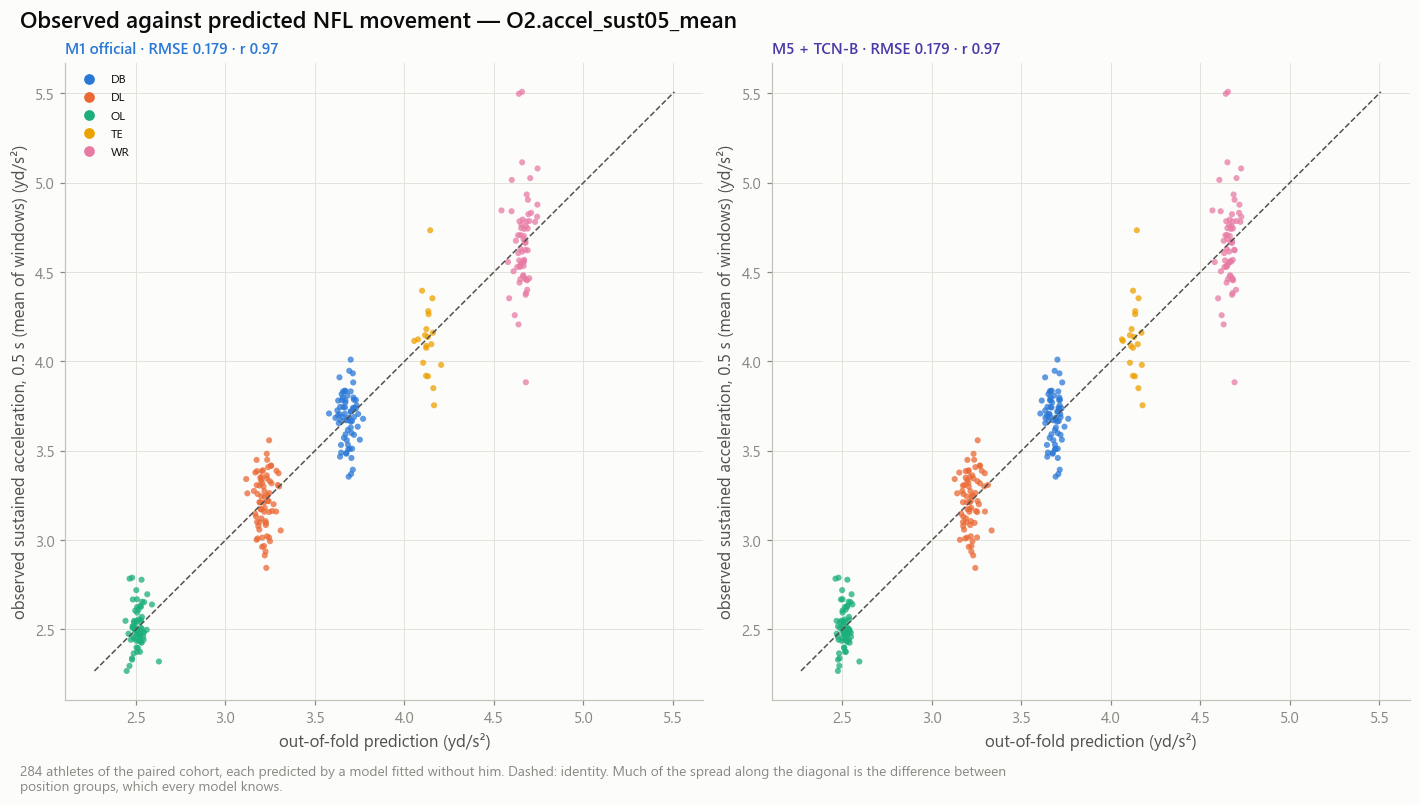

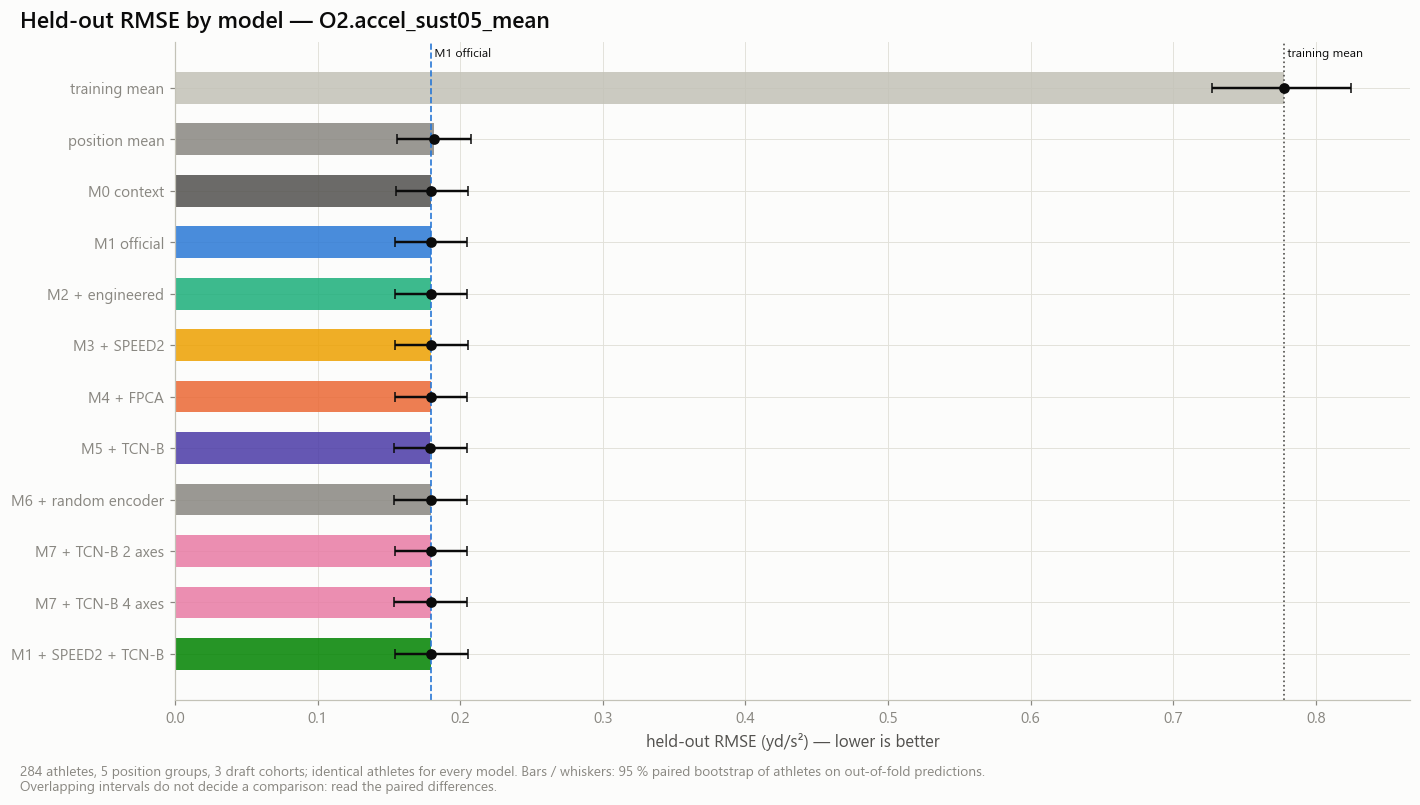

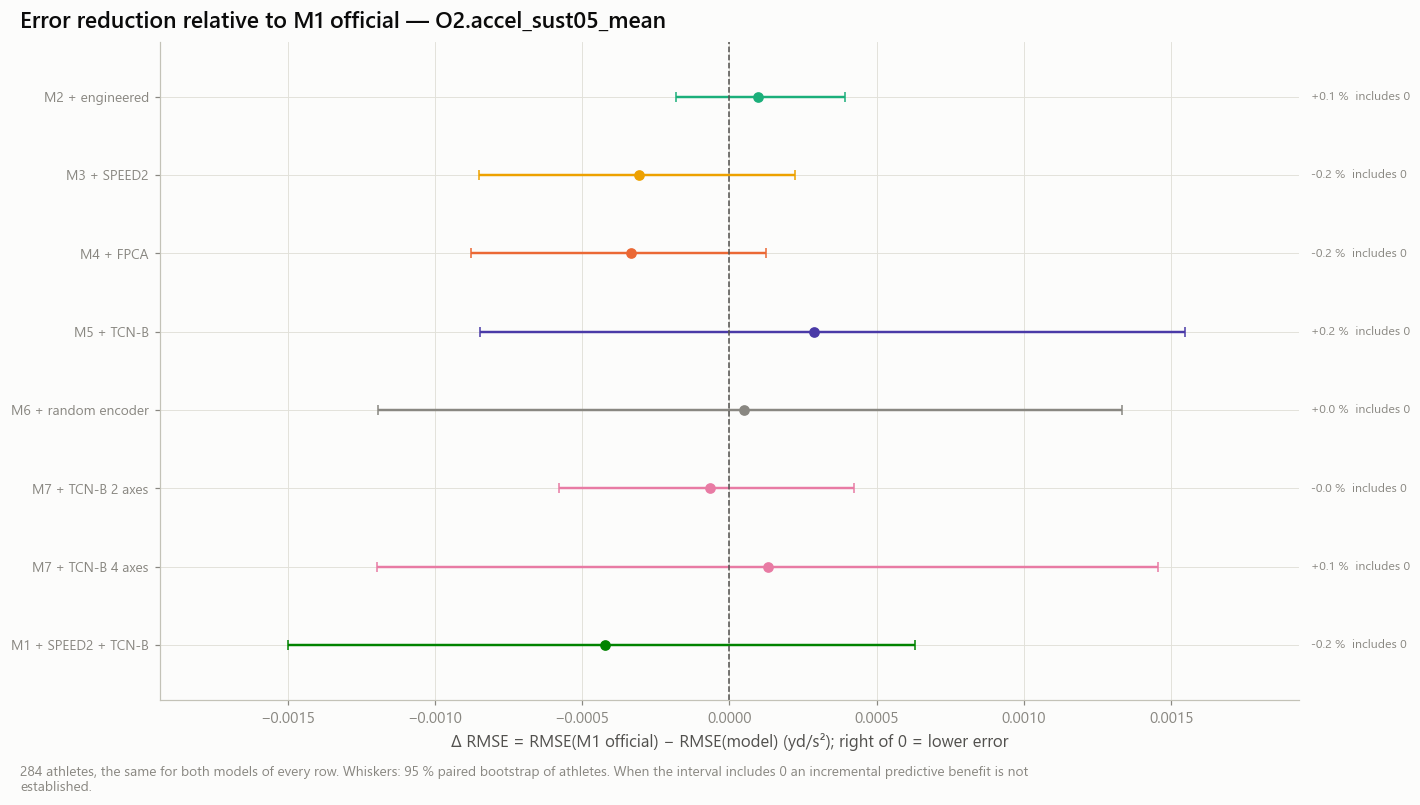

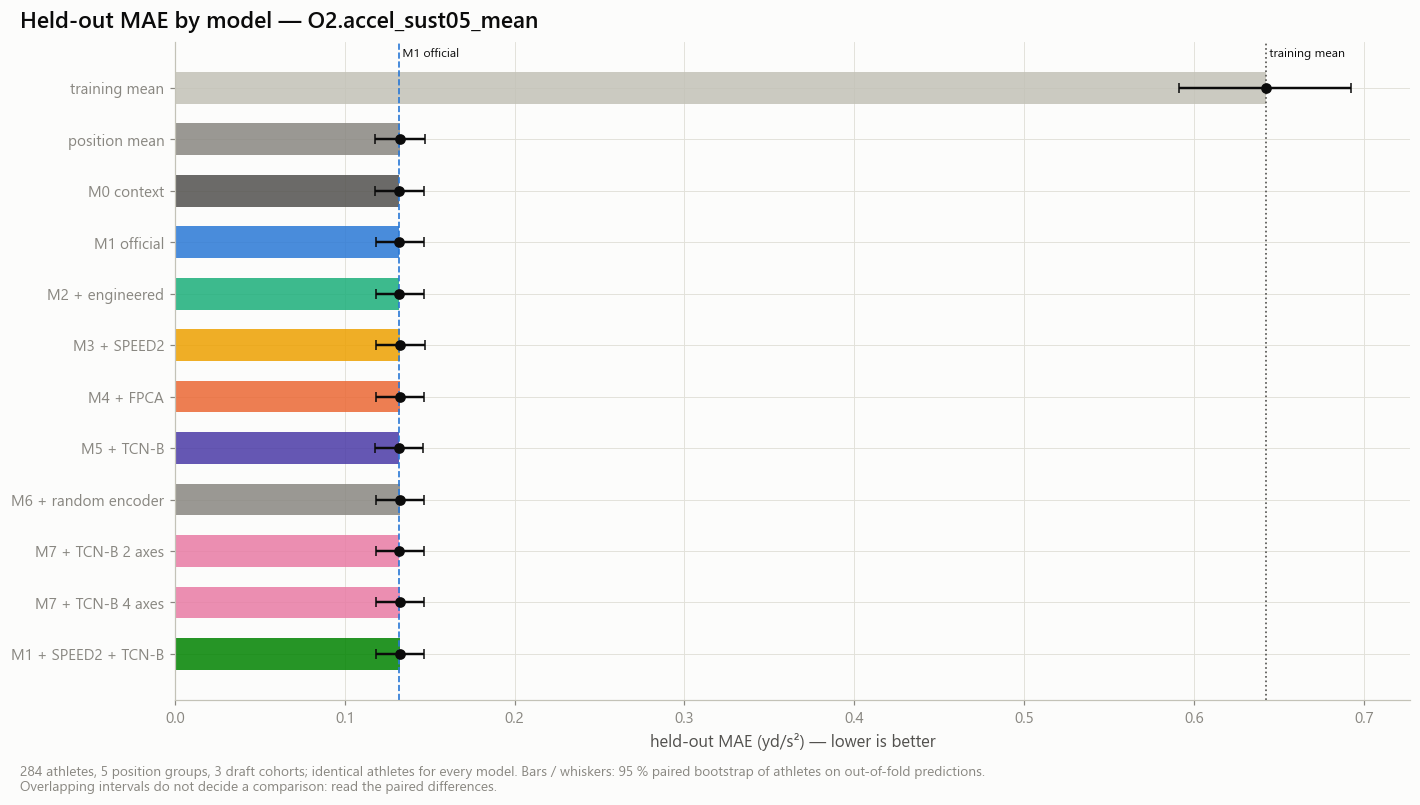

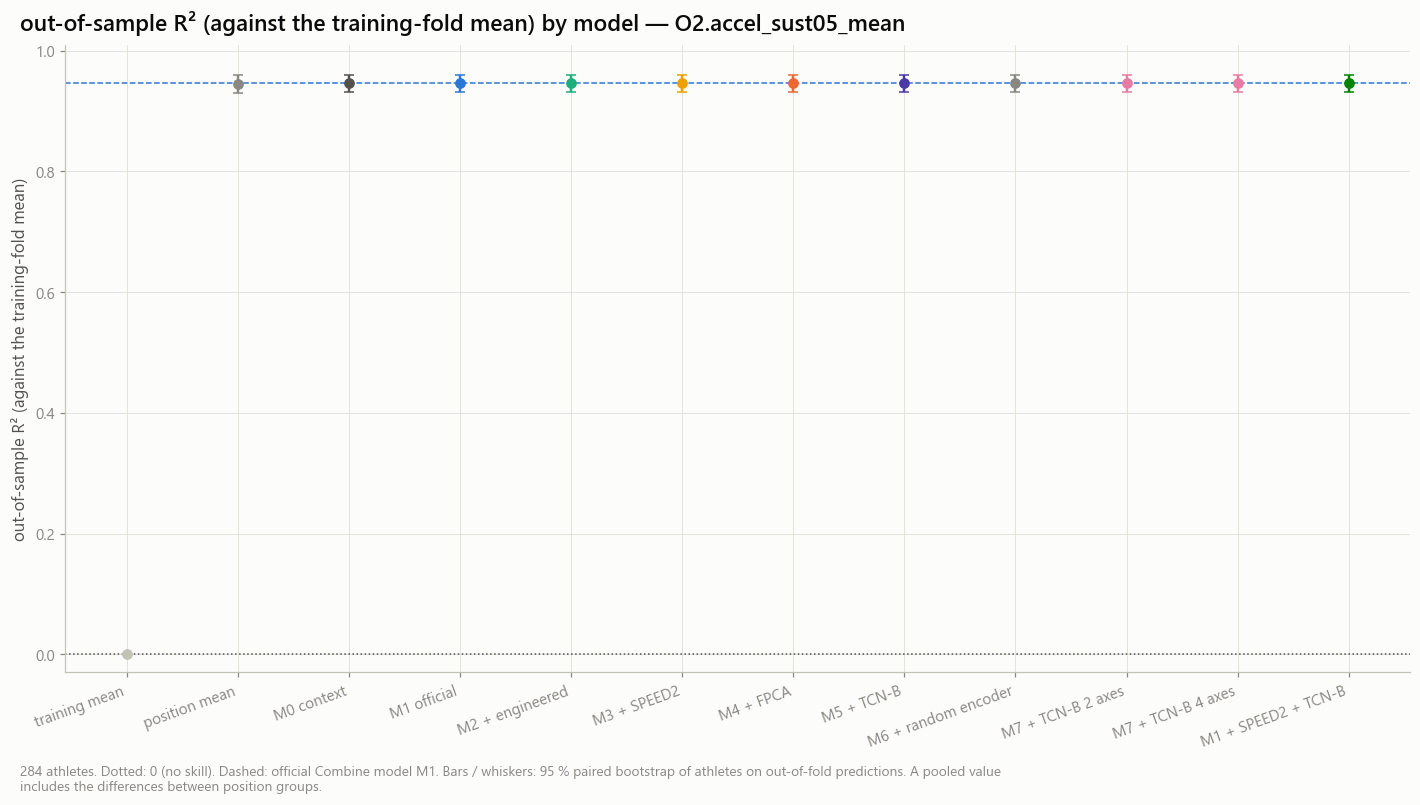

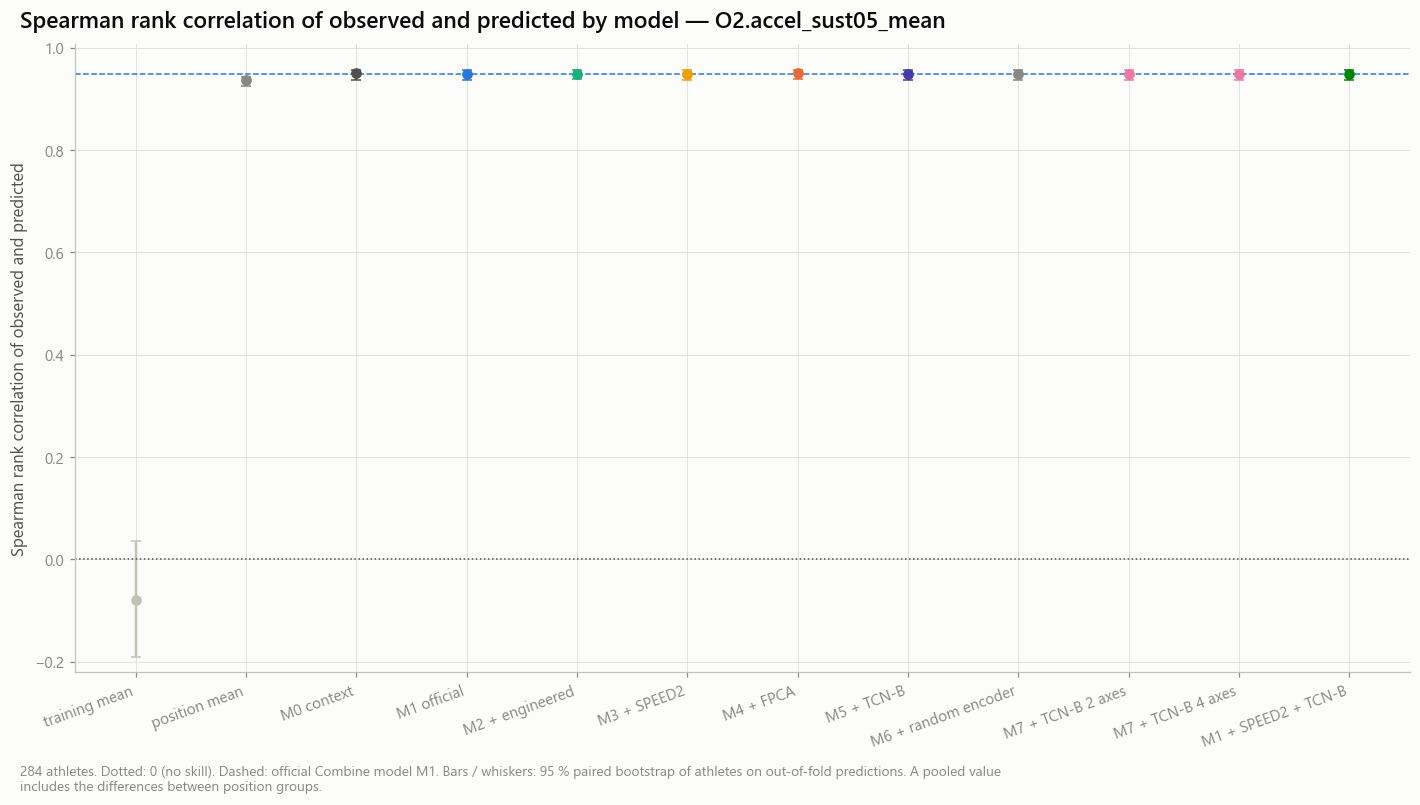

In [11]:
P, U = primary.target_id, primary.unit
N = int(oof.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY) & (pl.col('target_id') == P))['nfl_id'].n_unique())
NTXT, SRC = f'{N} athletes of the paired cohort', 'transfer_oof_predictions (notebook 06B)'
sel = lambda df: df.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY) & (pl.col('target_id') == P))
CORE = [m for m in ('M1', 'M2', 'M3', 'M4', 'M5', 'M6') if m in {x.model for x in MODELS}]

store.show(tf.plot_actual_vs_predicted(oof, P, ['M1', 'M5'], U, primary.label), 'AM06B_01_actual_vs_predicted_nfl_acceleration',
           {'oof': sel(oof).filter(pl.col('model').is_in(['M1', 'M5']))}, publication=True, source=SRC, n=NTXT)
store.show(tf.plot_error_metric(perf, P, 'rmse', U), 'AM06B_02_model_rmse_comparison', {'performance': sel(perf)}, publication=True, source=SRC, n=NTXT)
store.show(tf.plot_delta(paired, P, U), 'AM06B_03_delta_rmse_relative_to_m1', {'paired': sel(paired)}, publication=True, source=SRC, n=NTXT)
store.show(tf.plot_error_metric(perf, P, 'mae', U), 'AM06B_04_model_mae_comparison', {'performance': sel(perf)}, source=SRC, n=NTXT)
store.show(tf.plot_skill_metric(perf, P, 'r2_oos', 'out-of-sample R² (against the training-fold mean)'), 'AM06B_05_out_of_sample_r2',
           {'performance': sel(perf)}, source=SRC, n=NTXT)
store.show(tf.plot_skill_metric(perf, P, 'spearman', 'Spearman rank correlation of observed and predicted'), 'AM06B_06_spearman_ranking_comparison',
           {'performance': sel(perf)}, source=SRC, n=NTXT)

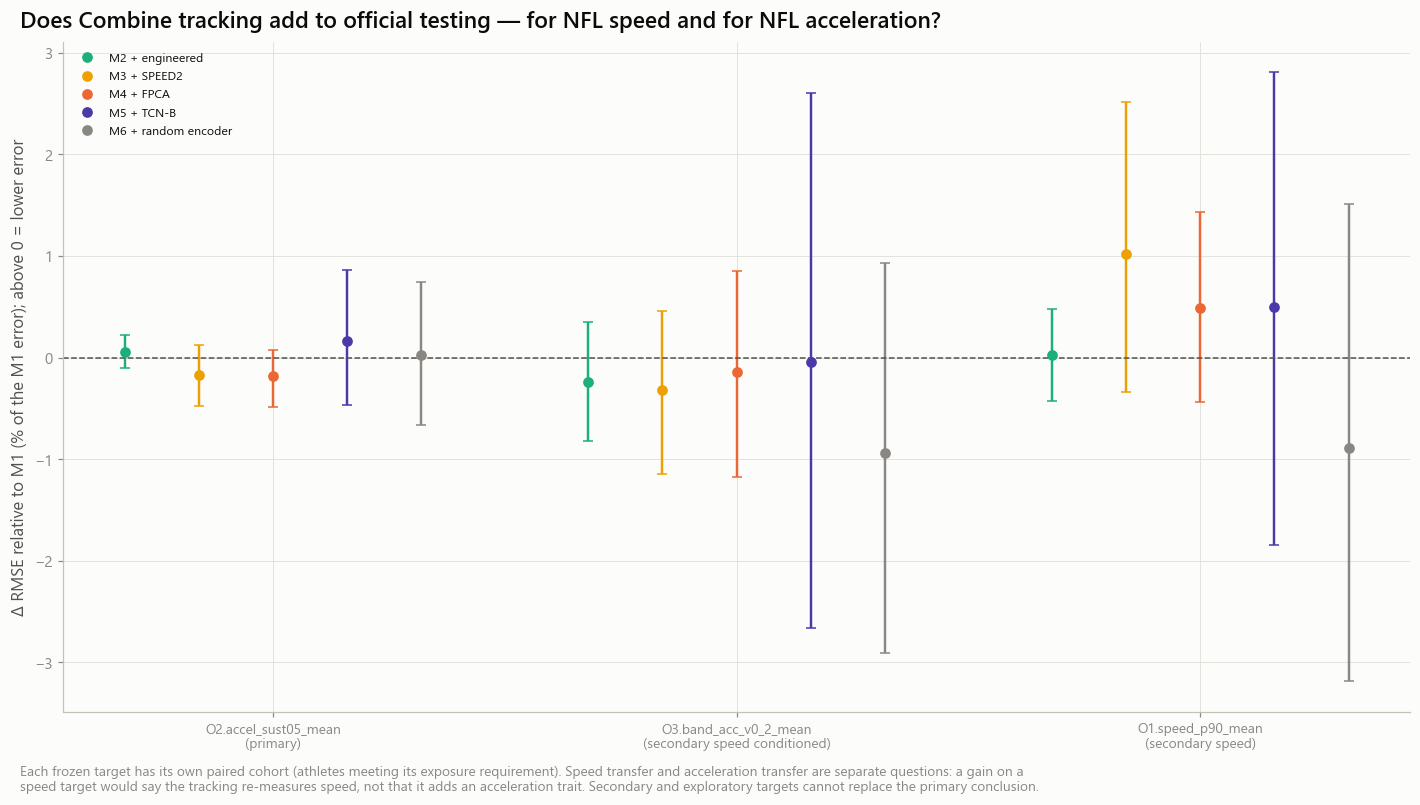

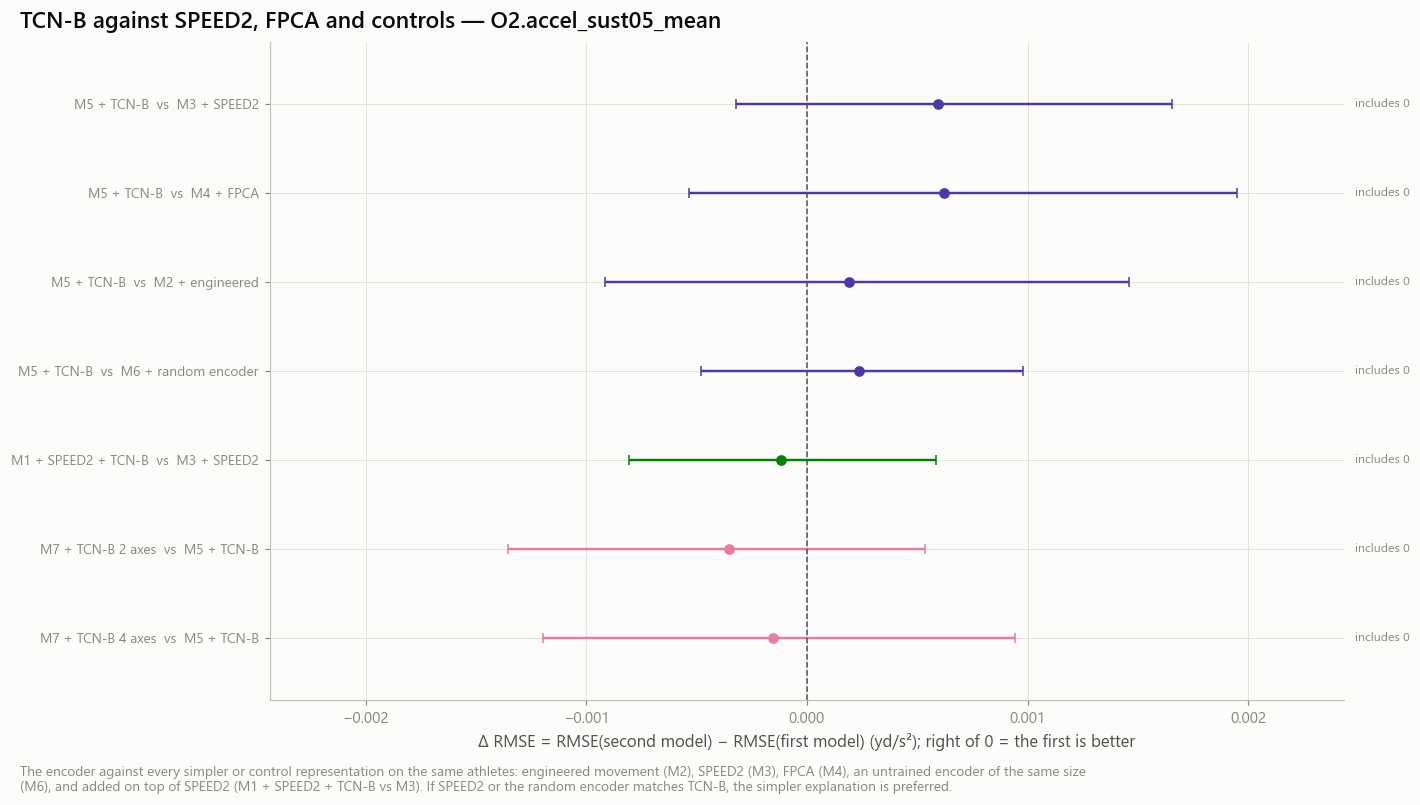

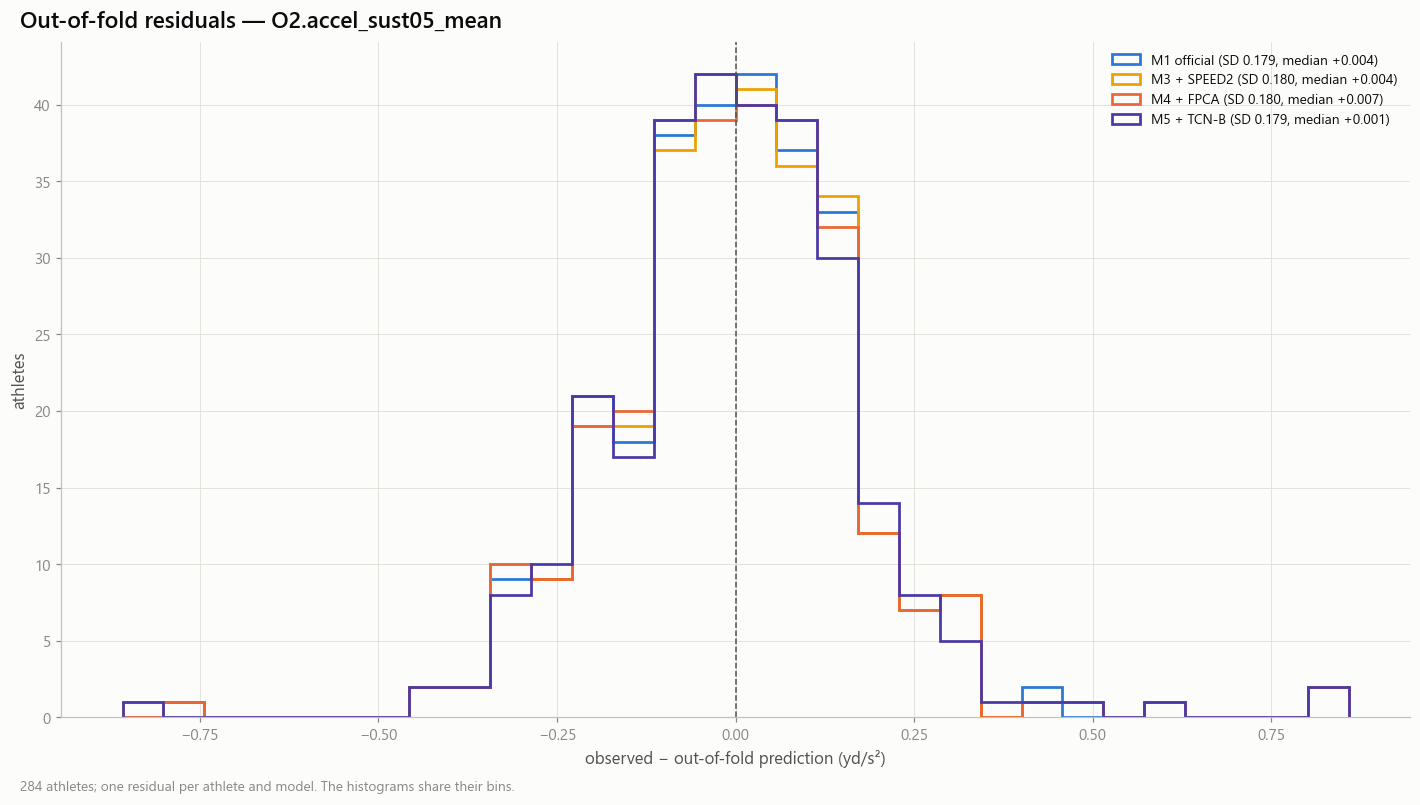

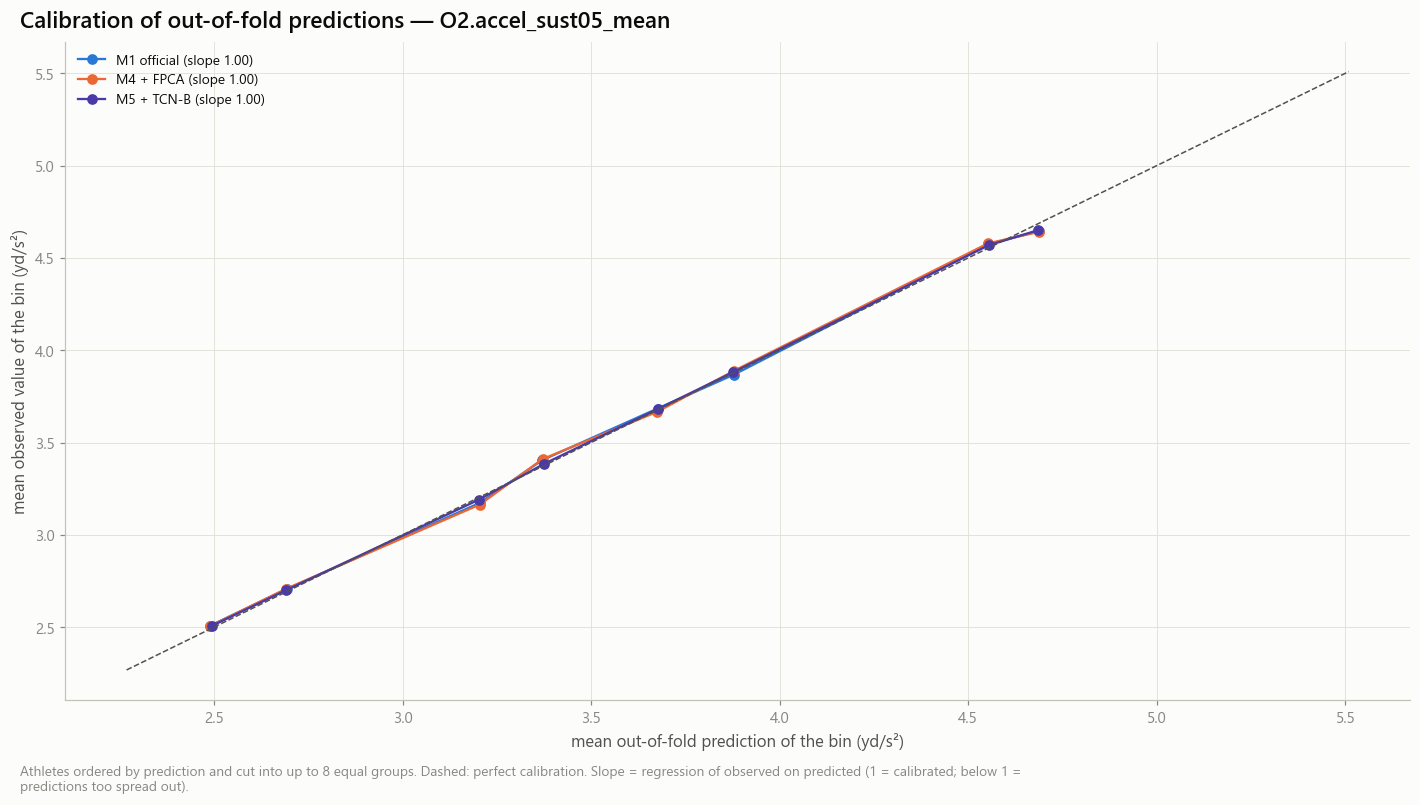

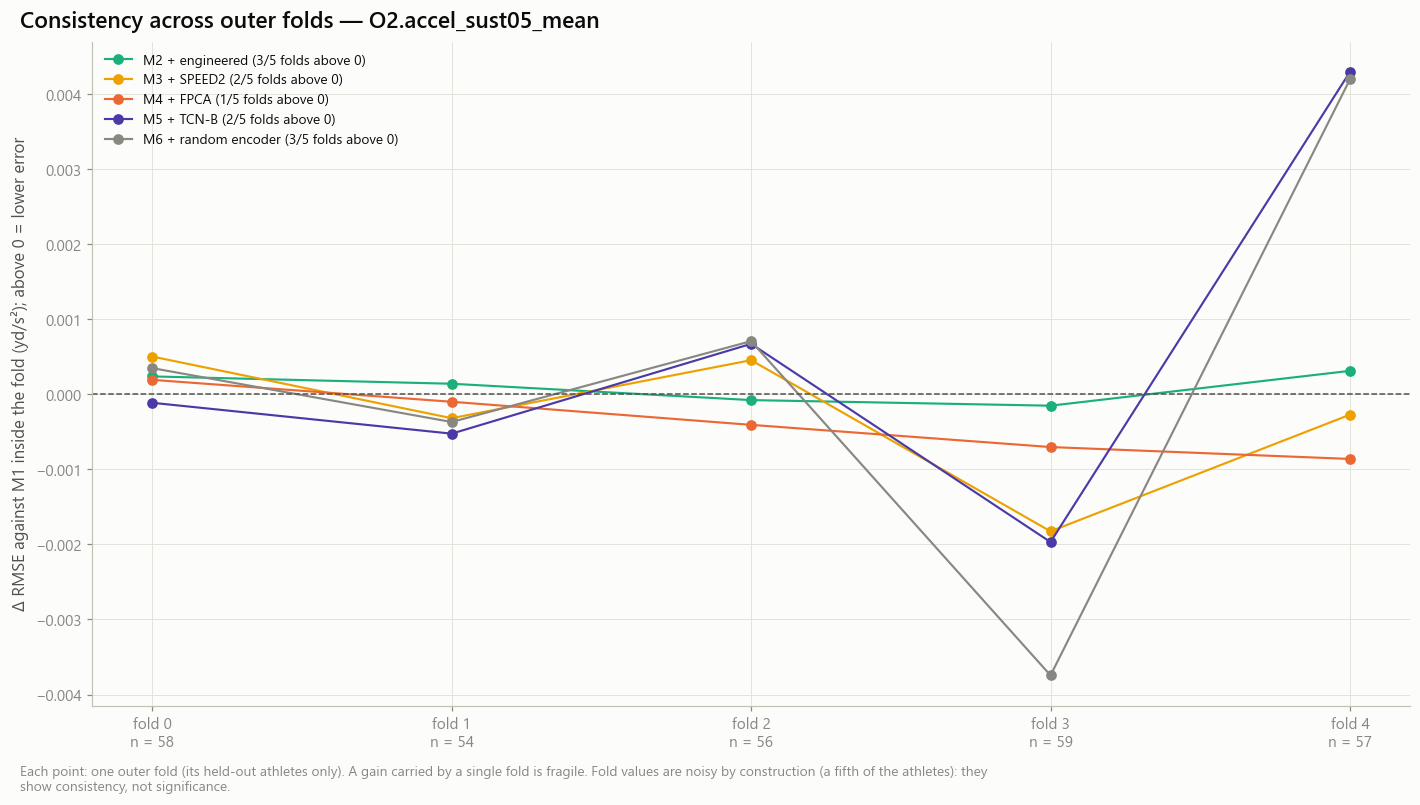

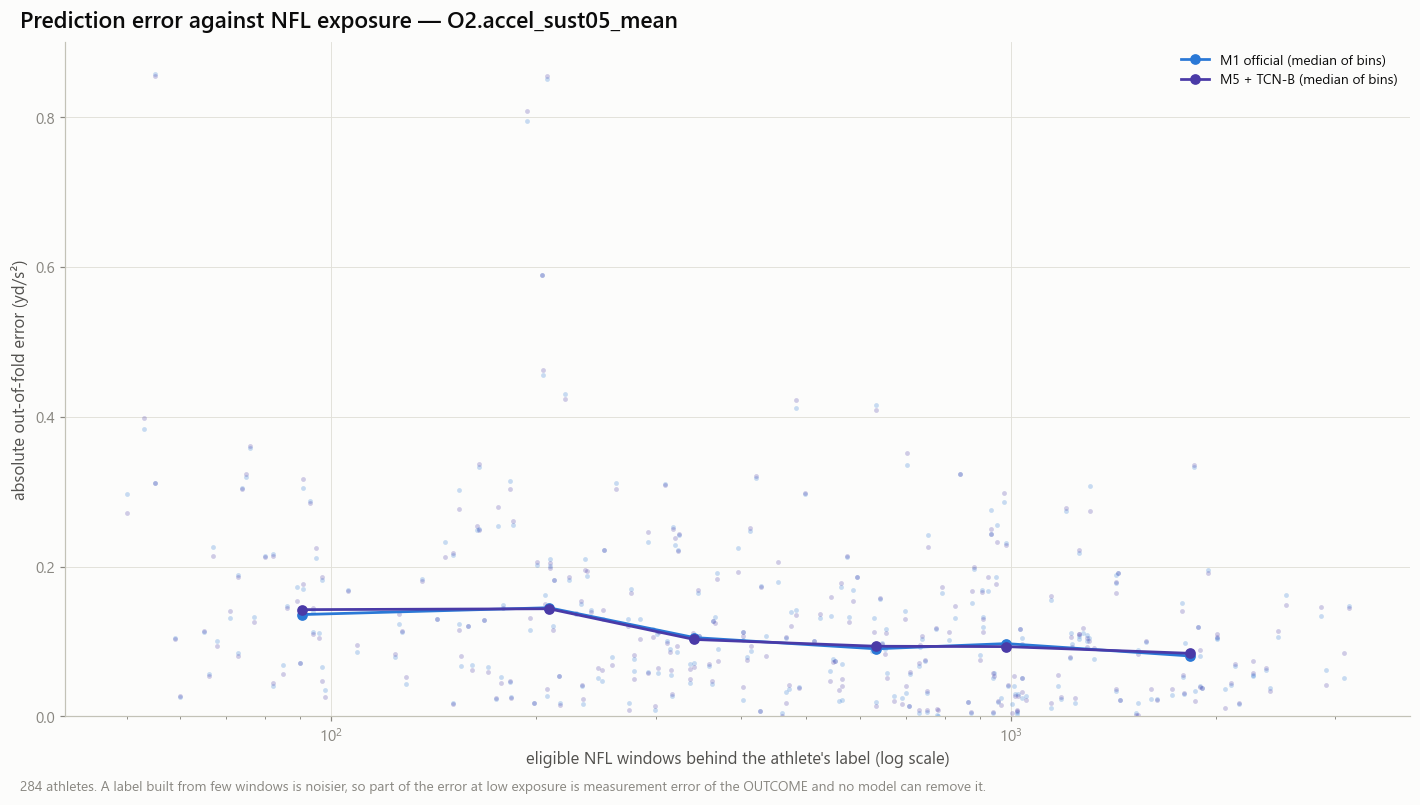

In [12]:
store.show(tf.plot_speed_vs_acceleration(paired, perf, [(t.target_id, t.study_role) for t in targets], [m for m in CORE if m != 'M1']),
           'AM06B_07_nfl_speed_vs_acceleration_transfer', {'paired': paired.filter((pl.col('analysis') == tm.PRIMARY) & (pl.col('cohort') == tm.PRIMARY))},
           publication=True, source=SRC, n='each frozen target on its own paired cohort')
CONTRAST = [('M5', 'M3'), ('M5', 'M4'), ('M5', 'M2'), ('M5', 'M6'), ('M5S', 'M3'), *[(f'M7_PC{k}', 'M5') for k in tc.compact_dims]]
store.show(tf.plot_representation_contrast(paired, P, U, CONTRAST), 'AM06B_08_tcn_vs_speed2_vs_fpca', {'paired': sel(paired)}, publication=True,
           source=SRC, n=NTXT)
store.show(tf.plot_residuals(oof, P, ['M1', 'M3', 'M4', 'M5'], U), 'AM06B_09_residual_distributions', {'oof': sel(oof)}, source=SRC, n=NTXT)
store.show(tf.plot_calibration(oof, perf, P, ['M1', 'M4', 'M5'], U), 'AM06B_10_calibration', {'performance': sel(perf)}, source=SRC, n=NTXT)
store.show(tf.plot_fold_performance(fold_perf, P, CORE, U), 'AM06B_11_performance_by_fold', {'fold_performance': sel(fold_perf)}, source=SRC, n=NTXT)
store.show(tf.plot_coverage_vs_error(oof, labels, P, ['M1', 'M5'], U), 'AM06B_12_coverage_vs_prediction_error', {'labels': sel(labels)}, source=SRC, n=NTXT)

## 9. Gate 06B — is the experiment valid?

Pass only if: identical held-out athletes for paired comparisons · the official baseline is included · the frozen feature candidates are used (block sizes match the shortlist) · representation fitting was inductive (no athlete shared between a fit and its held-out fold) · out-of-fold predictions are unique · uncertainty is reported.

**A positive result is not a criterion.** The gate says the experiment was executed correctly; what it found is read in the next cell.

In [13]:
GATE_B = replace(tr.GATE, name='transfer_gate_06b')
gate = tm.gate_06b(oof, paired, enc_fits, families, DIMS, P)
gate = store.write(gate, GATE_B, '06B', PROV) if controls.save_tables else conform(gate, GATE_B)
GATE_STATUS = 'PASS' if gate['passed'].all() else 'FAIL'
with pl.Config(fmt_str_lengths=220):
    display(gate)

reading = tm.conclusions_06b(perf, paired, targets, tc)
if controls.save_tables:
    (store.tables_dir / 'transfer_benchmark_conclusions.md').write_text(reading, encoding='utf-8')
    store.write_json('transfer_benchmark_manifest', {
        'notebook': PROV['notebook'], 'status': 'executed', 'gate_06b': GATE_STATUS, 'seed': controls.seed, 'targets_version_hash': TARGETS_HASH,
        'folds_hash': FOLDS_HASH, 'primary_target': P, 'n_paired_cohort': int(d.n), 'n_primary_target': N, 'models': [m.model for m in MODELS],
        'models_not_evaluable': skipped, 'block_dims': DIMS, 'encoder_configuration': tcfg.params(), 'encoder_configuration_source': config_source,
        'encoder_sources': enc_fits.group_by('family', 'source').len().to_dicts(), 'aggregation': tc.aggregation, 'transfer_config': tc.params(),
        'analyses': sorted(oof['analysis'].unique().to_list()), 'validation': validation_report.to_dicts(), 'nondeterminism': seed_notes,
        'executed_at': utc_now()})
tr.assert_gate(gate, '06B')
display(Markdown(f'### Gate 06B: {GATE_STATUS}'))
display(Markdown(reading))

11:42:39 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:06B] transfer_gate_06b: 6 rows → warehouse/gold/advanced_movement/transfer/transfer_gate_06b.parquet


criterion,passed,detail
str,bool,str
"""identical_heldout_athletes""",true,"""6 (cohort, target) group(s): every model on the same athletes"""
"""official_baseline_included""",true,"""models evaluated: ['M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'M5S', 'M6', 'M7_PC2', 'M7_PC4', 'MEAN', 'POS']"""
"""frozen_feature_candidates_used""",true,"""block sizes {'ENG': 1, 'FPCA': 2, 'RAND': 8, 'SPEED2': 2, 'TCN': 8, 'TCN_PC2': 2, 'TCN_PC4': 4}; frozen engineered ids ['F6.forty.time_v4_to_v8_s']"""
"""inductive_representation_fitting""",true,"""35 fold fits, 0 athlete(s) shared between a fit and its held-out fold"""
"""oof_predictions_unique""",true,"""one prediction per athlete, model, target and cohort"""
"""uncertainty_reported""",true,"""paired athlete-bootstrap interval of Δ RMSE (M5 − M1) on the primary target"""


### Gate 06B: PASS

### What the tables show (primary analysis, paired cohort)

- **`O2.accel_sust05_mean`** (primary, 284 athletes, yd/s²): M1 RMSE 0.179, R² +0.947.
    - M1 vs M0: Δ RMSE +0.000 [-0.002, +0.003], +0.1 % → not established (interval includes 0)
    - M2 vs M1: Δ RMSE +0.000 [-0.000, +0.000], +0.1 % → not established (interval includes 0)
    - M3 vs M1: Δ RMSE -0.000 [-0.001, +0.000], -0.2 % → not established (interval includes 0)
    - M4 vs M1: Δ RMSE -0.000 [-0.001, +0.000], -0.2 % → not established (interval includes 0)
    - M5 vs M1: Δ RMSE +0.000 [-0.001, +0.002], +0.2 % → not established (interval includes 0)
    - M5S vs M1: Δ RMSE -0.000 [-0.001, +0.001], -0.2 % → not established (interval includes 0)
    - M6 vs M1: Δ RMSE +0.000 [-0.001, +0.001], +0.0 % → not established (interval includes 0)
    - M7_PC2 vs M1: Δ RMSE -0.000 [-0.001, +0.000], -0.0 % → not established (interval includes 0)
    - M7_PC4 vs M1: Δ RMSE +0.000 [-0.001, +0.001], +0.1 % → not established (interval includes 0)
    - M5 vs M2: Δ RMSE +0.000 [-0.001, +0.001], +0.1 % → not established (interval includes 0)
    - M5 vs M3: Δ RMSE +0.001 [-0.000, +0.002], +0.3 % → not established (interval includes 0)
    - M5S vs M3: Δ RMSE -0.000 [-0.001, +0.001], -0.1 % → not established (interval includes 0)
    - M5 vs M4: Δ RMSE +0.001 [-0.001, +0.002], +0.3 % → not established (interval includes 0)
    - M7_PC2 vs M5: Δ RMSE -0.000 [-0.001, +0.001], -0.2 % → not established (interval includes 0)
    - M7_PC4 vs M5: Δ RMSE -0.000 [-0.001, +0.001], -0.1 % → not established (interval includes 0)
    - M5 vs M6: Δ RMSE +0.000 [-0.000, +0.001], +0.1 % → not established (interval includes 0)
    - POS vs MEAN: Δ RMSE +0.596 [+0.550, +0.640], +76.7 % → established
    - M0 vs POS: Δ RMSE +0.002 [-0.003, +0.006], +1.0 % → not established (interval includes 0)
- **`O3.band_acc_v0_2_mean`** (secondary_speed_conditioned, 284 athletes, yd/s²): M1 RMSE 0.191, R² +0.937.
    - M1 vs M0: Δ RMSE +0.001 [-0.004, +0.007], +0.7 % → not established (interval includes 0)
    - M2 vs M1: Δ RMSE -0.000 [-0.002, +0.001], -0.2 % → not established (interval includes 0)
    - M3 vs M1: Δ RMSE -0.001 [-0.002, +0.001], -0.3 % → not established (interval includes 0)
    - M4 vs M1: Δ RMSE -0.000 [-0.002, +0.002], -0.1 % → not established (interval includes 0)
    - M5 vs M1: Δ RMSE -0.000 [-0.005, +0.005], -0.0 % → not established (interval includes 0)
    - M5S vs M1: Δ RMSE +0.002 [-0.004, +0.007], +0.9 % → not established (interval includes 0)
    - M6 vs M1: Δ RMSE -0.002 [-0.006, +0.002], -0.9 % → not established (interval includes 0)
    - M7_PC2 vs M1: Δ RMSE +0.001 [-0.001, +0.004], +0.7 % → not established (interval includes 0)
    - M7_PC4 vs M1: Δ RMSE +0.001 [-0.004, +0.005], +0.3 % → not established (interval includes 0)
    - M5 vs M2: Δ RMSE +0.000 [-0.005, +0.006], +0.2 % → not established (interval includes 0)
    - M5 vs M3: Δ RMSE +0.001 [-0.005, +0.006], +0.3 % → not established (interval includes 0)
    - M5S vs M3: Δ RMSE +0.002 [-0.004, +0.008], +1.2 % → not established (interval includes 0)
    - M5 vs M4: Δ RMSE +0.000 [-0.006, +0.006], +0.1 % → not established (interval includes 0)
    - M7_PC2 vs M5: Δ RMSE +0.001 [-0.002, +0.005], +0.8 % → not established (interval includes 0)
    - M7_PC4 vs M5: Δ RMSE +0.001 [-0.001, +0.002], +0.3 % → not established (interval includes 0)
    - M5 vs M6: Δ RMSE +0.002 [-0.004, +0.008], +0.9 % → not established (interval includes 0)
    - POS vs MEAN: Δ RMSE +0.531 [+0.484, +0.577], +69.9 % → established
    - M0 vs POS: Δ RMSE +0.036 [+0.022, +0.051], +15.8 % → established
- **`O1.speed_p90_mean`** (secondary_speed, 284 athletes, yd/s): M1 RMSE 0.275, R² +0.961.
    - M1 vs M0: Δ RMSE -0.004 [-0.010, +0.001], -1.5 % → not established (interval includes 0)
    - M2 vs M1: Δ RMSE +0.000 [-0.001, +0.001], +0.0 % → not established (interval includes 0)
    - M3 vs M1: Δ RMSE +0.003 [-0.001, +0.007], +1.0 % → not established (interval includes 0)
    - M4 vs M1: Δ RMSE +0.001 [-0.001, +0.004], +0.5 % → not established (interval includes 0)
    - M5 vs M1: Δ RMSE +0.001 [-0.005, +0.008], +0.5 % → not established (interval includes 0)
    - M5S vs M1: Δ RMSE +0.001 [-0.005, +0.007], +0.4 % → not established (interval includes 0)
    - M6 vs M1: Δ RMSE -0.002 [-0.009, +0.004], -0.9 % → not established (interval includes 0)
    - M7_PC2 vs M1: Δ RMSE +0.004 [-0.000, +0.008], +1.4 % → not established (interval includes 0)
    - M7_PC4 vs M1: Δ RMSE -0.001 [-0.007, +0.006], -0.2 % → not established (interval includes 0)
    - M5 vs M2: Δ RMSE +0.001 [-0.005, +0.008], +0.5 % → not established (interval includes 0)
    - M5 vs M3: Δ RMSE -0.001 [-0.007, +0.004], -0.5 % → not established (interval includes 0)
    - M5S vs M3: Δ RMSE -0.002 [-0.007, +0.004], -0.6 % → not established (interval includes 0)
    - M5 vs M4: Δ RMSE +0.000 [-0.005, +0.006], +0.0 % → not established (interval includes 0)
    - M7_PC2 vs M5: Δ RMSE +0.003 [-0.001, +0.007], +1.0 % → not established (interval includes 0)
    - M7_PC4 vs M5: Δ RMSE -0.002 [-0.005, +0.001], -0.7 % → not established (interval includes 0)
    - M5 vs M6: Δ RMSE +0.004 [-0.002, +0.010], +1.4 % → not established (interval includes 0)
    - POS vs MEAN: Δ RMSE +1.076 [+1.000, +1.145], +77.1 % → established
    - M0 vs POS: Δ RMSE +0.049 [+0.028, +0.069], +15.3 % → established

Δ RMSE = RMSE(reference) − RMSE(model); positive = lower error than the reference. Intervals: paired bootstrap of athletes (2000 replicates) on out-of-fold predictions. A gain below 2 % of the reference error is not treated as practically relevant (heuristic). Exploratory rows (M7, M5S, secondary targets) cannot replace the primary comparison M5 vs M1 on the primary target.

## 10. How to read this notebook, and what it does not show

- The **primary conclusion** is the row *M5 vs M1* on the primary frozen target in the reading above, with its interval. Everything else is context for it.
- If that interval includes 0: *an incremental predictive benefit of TCN-B over official Combine testing is not established on this cohort.* That is a valid outcome of Milestone 06.
- If M3 (SPEED2) or M6 (random encoder) does as well as M5, the simpler explanation holds: tracking re-measures speed, or any re-coding of the curve helps.
- A pooled R² or Spearman includes the differences between position groups; the paired Δ RMSE does not, because both models know the position.
- The label is *observed* NFL movement: role, scheme and usage are part of it. Reliability across games (Milestone 05) does not make it a pure athletic capability.
- Intervals cover athlete sampling, not the refitting of the models or of the encoders (one training seed here; replicates are in 06C).

**Outputs** (`…/advanced_movement/transfer/`): `transfer_attempt_representations_outer`, `transfer_encoder_fits_outer`, fold encoders `transfer/tcn/*.pt`, `transfer_common_support`, `transfer_oof_predictions`, `transfer_oof_targets`, `transfer_fold_preprocessing`, `transfer_model_performance`, `transfer_paired_comparisons`, `transfer_fold_performance`, `transfer_gate_06b`, `transfer_benchmark_conclusions.md`, `transfer_benchmark_manifest.json`, figures `AM06B_01`–`AM06B_12`.

**Next:** `06c_transfer_robustness_and_scouting_insights.ipynb` in the same `RUN_MODE` — positions, draft cohorts, exposure and context rules, matched prospects, null controls, and the scoring-readiness registry. No scoring system is built before that.